**MÔ HÌNH CNN PHÂN LOẠI CẢNH QUAN**
*   Lưu ý: Đọc kỹ ghi chú trước khi sử dụng, Up hết các file cần thiết để test mô hình
 Không chạy tất cả, phải chạy lần lượt từng bước. **Đọc kỹ ghi chú trước khi sử dụng**
** Có 2 cách test mô hình**. ***Thứ nhất*** chạy trực tiếp mô hình trên google Colab, cần phải up đầy đủ các file cần thiết như "baseline_model.keras", "baseline_history.pkl", dataset.zip và các ảnh liên quan để test. ***Cách thứ hai*** là truy cập theo đường link: https://huggingface.co/spaces/Dastsimcu/CNN Nếu trang web đang ngủ thì hãy bấm **restart** và đợi vài phút. Sau đó chỉ cần upload hình ảnh lên và test




**LOAD LỊCH SỬ TRAIN MODEL**

In [ ]:
from tensorflow.keras.models import load_model #load model CNN
baseline_model = load_model("baseline_model.keras")

In [ ]:
import joblib #load lịch sử
history = joblib.load("baseline_history.pkl")
print(history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


**THÊM THƯ VIỆN HỖ TRỢ**

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path
with zipfile.ZipFile("dataset.zip", "r") as zip_ref:
  zip_ref.extractall("/content/")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score
)
from sklearn.preprocessing import label_binarize

import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

BASE_DIR = Path("/content")
TRAIN_DIR = BASE_DIR / "train"
TEST_DIR = BASE_DIR / "test"
VAL_DIR = BASE_DIR / "val"
print(f"Train directory: {TRAIN_DIR}")
print(f"Test directory:  {TEST_DIR}")
print(f"Train classes:   {sorted(os.listdir(TRAIN_DIR))}")

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train directory: /content/train
Test directory:  /content/test
Train classes:   ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
IMG_SIZE    = 150
BATCH_SIZE  = 32
CLASS_NAMES = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(CLASS_NAMES)

print(f"Cảnh quan {CLASS_NAMES}")

Cảnh quan ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
train_counts = {}
test_counts  = {}

for cls in CLASS_NAMES:
    train_counts[cls] = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    test_counts[cls]  = len(os.listdir(os.path.join(TEST_DIR, cls)))

stats_df = pd.DataFrame({
    'Cảnh quan': CLASS_NAMES,
    'Train': [train_counts[c] for c in CLASS_NAMES],
    'Test':  [test_counts[c]  for c in CLASS_NAMES]
})
stats_df['Total'] = stats_df['Train'] + stats_df['Test']
stats_df.loc[len(stats_df)] = ['Total', stats_df['Train'].sum(),stats_df['Test'].sum(), stats_df['Total'].sum()]
print(stats_df.to_string(index=False))

Cảnh quan  Train  Test  Total
buildings   1972   437   2409
   forest   2044   474   2518
  glacier   2164   553   2717
 mountain   2261   525   2786
      sea   2047   510   2557
   street   2144   501   2645
    Total  12632  3000  15632


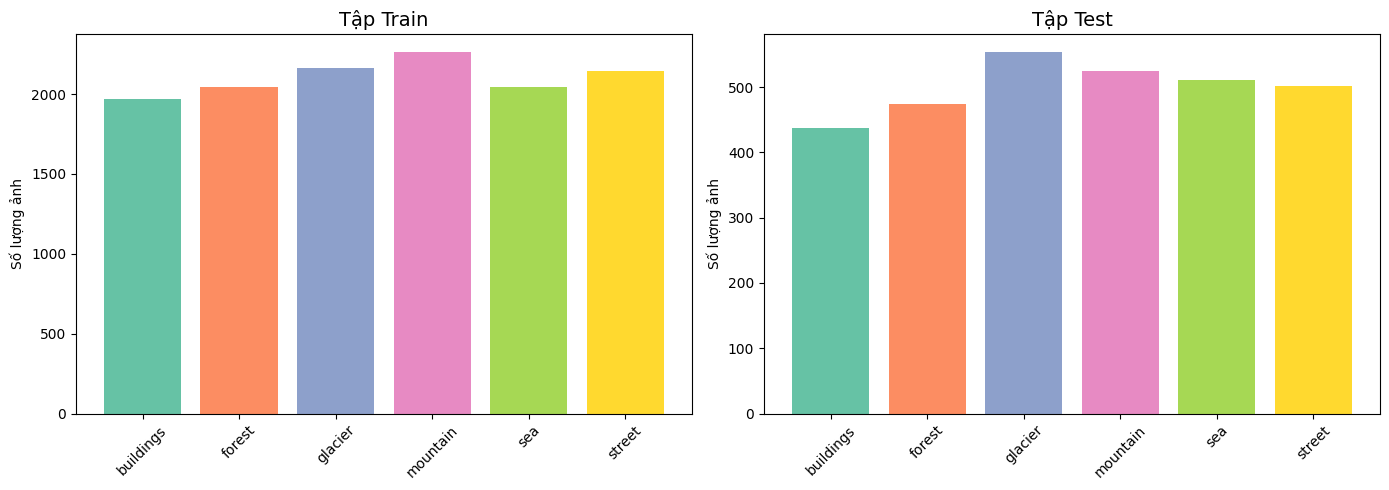

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette('Set2', NUM_CLASSES)

axes[0].bar(CLASS_NAMES, [train_counts[c] for c in CLASS_NAMES], color=colors)
axes[0].set_title('Tập Train', fontsize=14)
axes[0].set_ylabel('Số lượng ảnh')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(CLASS_NAMES, [test_counts[c] for c in CLASS_NAMES], color=colors)
axes[1].set_title('Tập Test', fontsize=14)
axes[1].set_ylabel('Số lượng ảnh')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

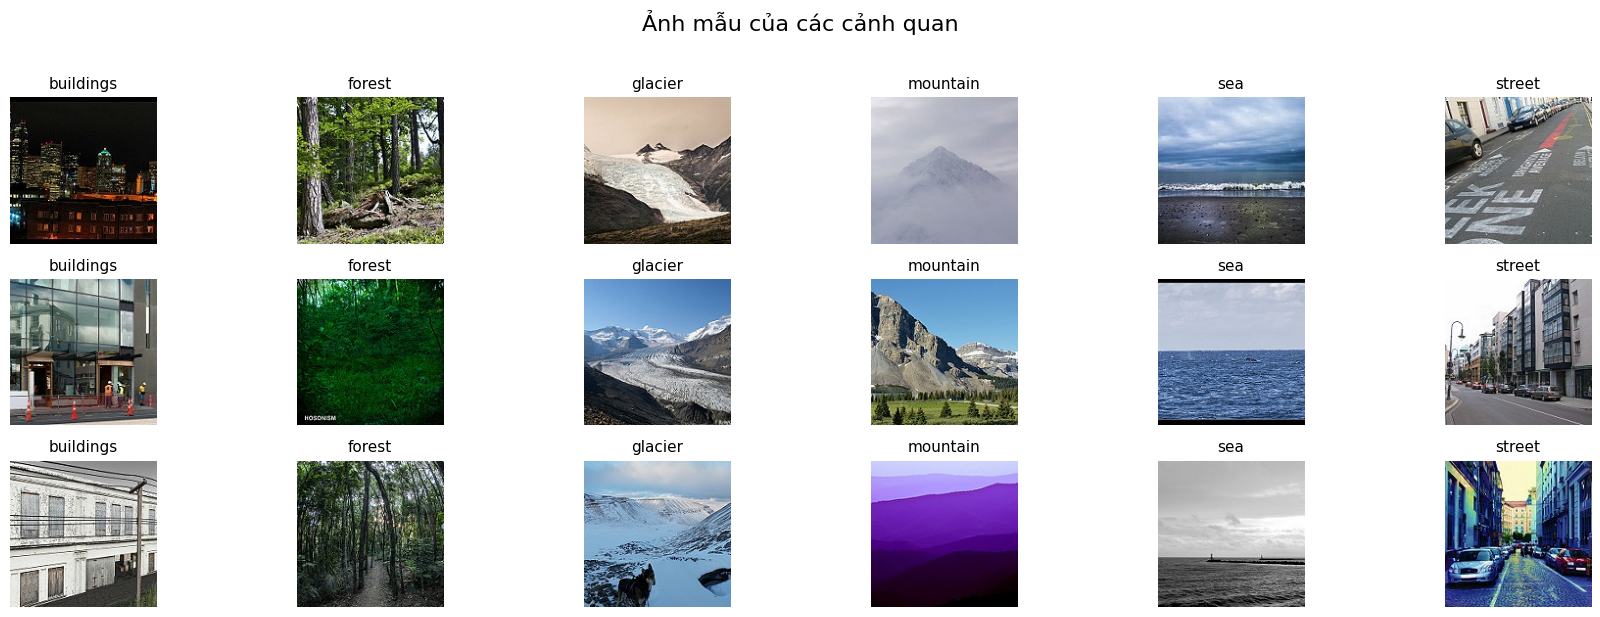

In [ ]:
fig, axes = plt.subplots(3, 6, figsize=(18, 6))
fig.suptitle('Ảnh mẫu của các cảnh quan', fontsize=16, y=1.02)

for i, cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    samples = random.sample(os.listdir(cls_dir), 3)
    for j in range(3):
        img = keras.utils.load_img(os.path.join(cls_dir, samples[j]),
                                    target_size=(IMG_SIZE, IMG_SIZE))
        axes[j, i].imshow(img)
        axes[j, i].set_title(cls, fontsize=11)
        axes[j, i].axis('off')

plt.tight_layout()
plt.show()

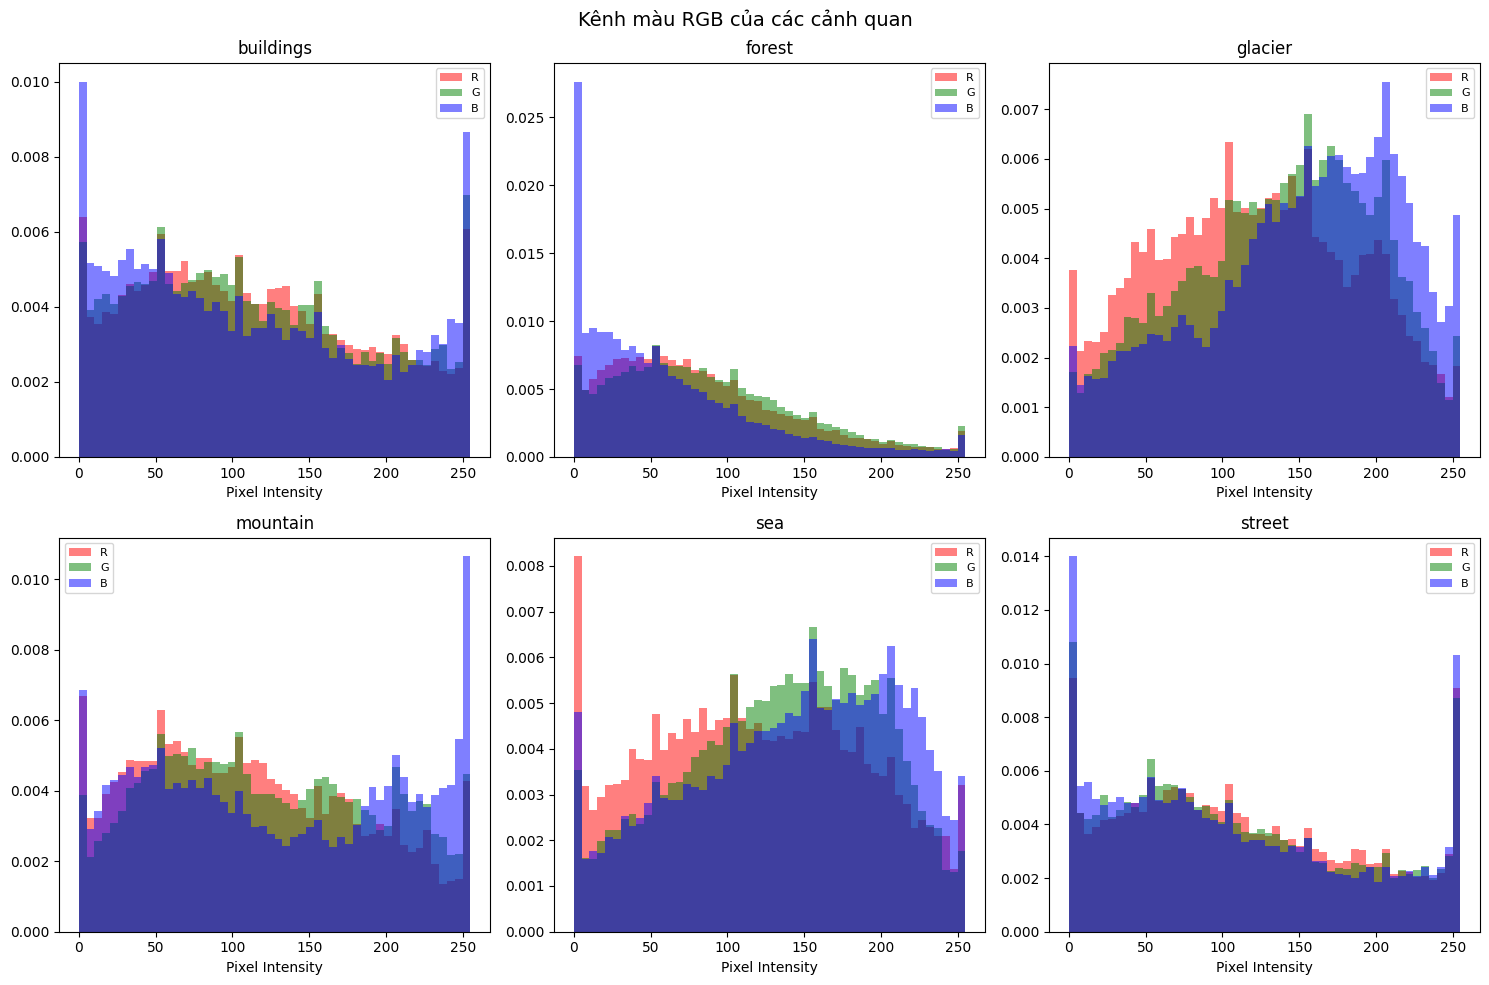

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    sample_files = random.sample(os.listdir(cls_dir), min(100, len(os.listdir(cls_dir))))

    r_vals, g_vals, b_vals = [], [], []
    for f in sample_files:
        img = keras.utils.load_img(os.path.join(cls_dir, f), target_size=(IMG_SIZE, IMG_SIZE))
        arr = np.array(img)
        r_vals.extend(arr[:,:,0].flatten()[::50])
        g_vals.extend(arr[:,:,1].flatten()[::50])
        b_vals.extend(arr[:,:,2].flatten()[::50])

    axes[idx].hist(r_vals, bins=50, alpha=0.5, color='red',   label='R', density=True)
    axes[idx].hist(g_vals, bins=50, alpha=0.5, color='green', label='G', density=True)
    axes[idx].hist(b_vals, bins=50, alpha=0.5, color='blue',  label='B', density=True)
    axes[idx].set_title(f'{cls}', fontsize=12)
    axes[idx].legend(fontsize=8)
    axes[idx].set_xlabel('Pixel Intensity')

fig.suptitle('Kênh màu RGB của các cảnh quan', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
print(VAL_DIR)
print(os.listdir(VAL_DIR))

/content/val
['forest', 'glacier', 'sea', 'mountain', 'buildings', 'street']


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    horizontal_flip=True,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

# Test generator — only rescaling
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED,
    shuffle=True
)

val_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED,
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\nTrain samples:      {train_gen.samples}")
print(f"Validation samples: {val_gen.samples}")
print(f"Test samples:       {test_gen.samples}")
print(f"Class indices:      {train_gen.class_indices}")

Found 10109 images belonging to 6 classes.
Found 2523 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.

Train samples:      10109
Validation samples: 2523
Test samples:       3000
Class indices:      {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


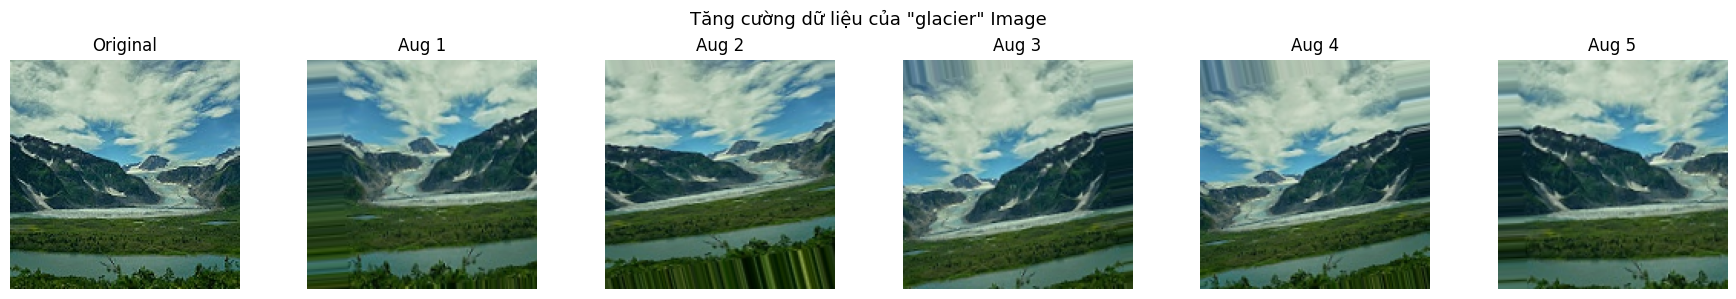

In [ ]:
sample_cls = CLASS_NAMES[2]
sample_img_path = os.path.join(TRAIN_DIR, sample_cls, os.listdir(os.path.join(TRAIN_DIR, sample_cls))[0])
sample_img = keras.utils.load_img(sample_img_path, target_size=(IMG_SIZE, IMG_SIZE))
sample_arr = np.expand_dims(np.array(sample_img), 0)

aug_gen = ImageDataGenerator(
    horizontal_flip=True, rotation_range=15,
    width_shift_range=0.15, height_shift_range=0.15, zoom_range=0.15
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
fig.suptitle(f'Tăng cường dữ liệu của "{sample_cls}" Image', fontsize=13)
axes[0].imshow(sample_img); axes[0].set_title('Original'); axes[0].axis('off')

it = aug_gen.flow(sample_arr, batch_size=1)
for i in range(1, 6):
    axes[i].imshow(next(it)[0].astype('uint8'))
    axes[i].set_title(f'Aug {i}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#load model bằng keras không chạy cái này
#load model bằng keras không chạy cái này
def build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES): #load model bằng keras không chạy cái này
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=input_shape),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),

        # Block 2
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),

        # Block 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D((2,2)),

        # Classifier head
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    10,617,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,905,638 (41.60 MB)

 Trainable params: 10,905,638 (41.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#load model bằng keras không chạy cái này
#load model bằng keras không chạy cái này
#load model bằng keras không chạy cái này
#load model bằng keras không chạy cái này
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

baseline_callbacks = [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss'),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-6)
]

EPOCHS = 25

baseline_history = baseline_model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=baseline_callbacks,
    verbose=1
)

Epoch 1/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 112s 318ms/step - accuracy: 0.5464 - loss: 1.1142 - val_accuracy: 0.6465 - val_loss: 0.9100 - learning_rate: 0.0010
Epoch 2/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 87s 276ms/step - accuracy: 0.6305 - loss: 0.9070 - val_accuracy: 0.6385 - val_loss: 0.8930 - learning_rate: 0.0010
Epoch 3/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 87s 274ms/step - accuracy: 0.6929 - loss: 0.7970 - val_accuracy: 0.7396 - val_loss: 0.7088 - learning_rate: 0.0010
Epoch 4/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 87s 275ms/step - accuracy: 0.7487 - loss: 0.6760 - val_accuracy: 0.7840 - val_loss: 0.5924 - learning_rate: 0.0010
Epoch 5/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 86s 272ms/step - accuracy: 0.7706 - loss: 0.6212 - val_accuracy: 0.7808 - val_loss: 0.6173 - learning_rate: 0.0010
Epoch 6/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 85s 270ms/step - accuracy: 0.8006 - loss: 0.5435 - val_accuracy: 0.8109 - val_loss: 0.5336 - learning_rate: 0.0010
Epoch 7/25
316/316 ━━━━━━━━━━━━━━━━━━━━ 87s 274ms/step - accuracy: 0.

In [ ]:
test_loss, test_acc = baseline_model.evaluate(test_gen, verbose=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8757 - loss: 0.3569


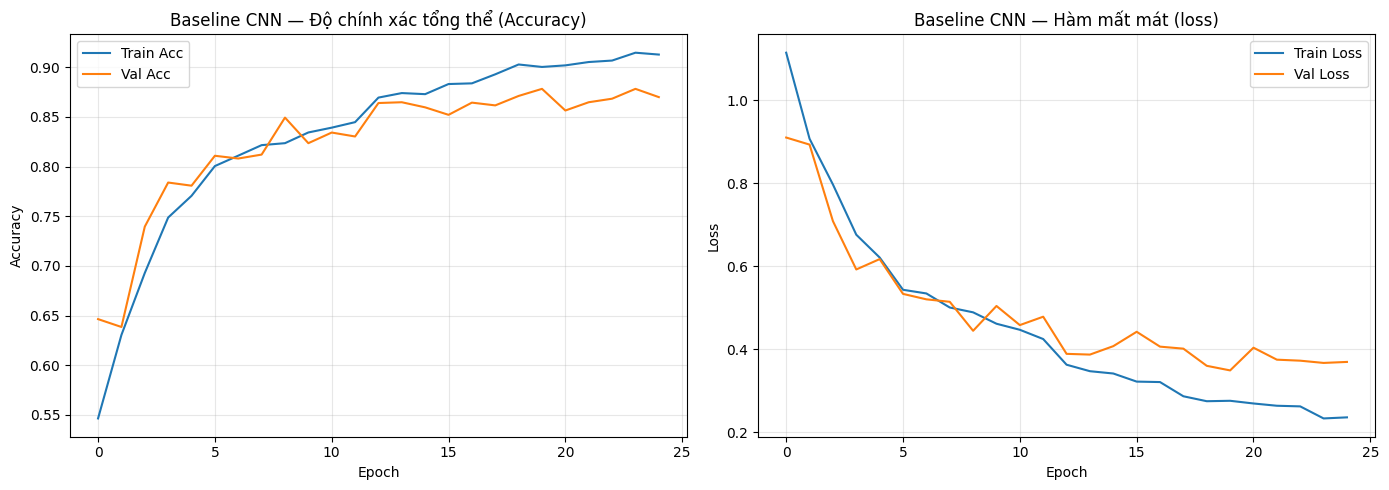

In [ ]:
#loadmodel bằng keras không chạy cái này
#loadmodel bằng keras không chạy cái này
#loadmodel bằng keras không chạy cái này
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'],     label='Train Acc')
    axes[0].plot(history.history['val_accuracy'],  label='Val Acc')
    axes[0].set_title(f'{title} — Độ chính xác tổng thể (Accuracy)')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train Loss')
    axes[1].plot(history.history['val_loss'],  label='Val Loss')
    axes[1].set_title(f'{title} — Hàm mất mát (loss)')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(baseline_history, 'Baseline CNN')

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step


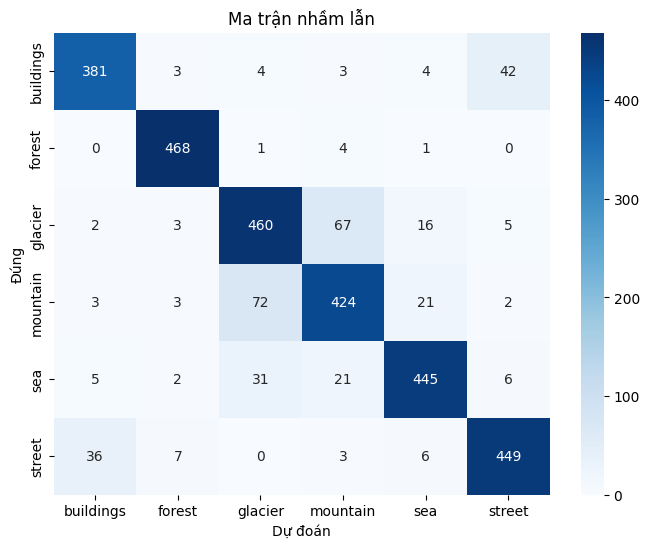

              precision    recall  f1-score   support

   buildings       0.89      0.87      0.88       437
      forest       0.96      0.99      0.97       474
     glacier       0.81      0.83      0.82       553
    mountain       0.81      0.81      0.81       525
         sea       0.90      0.87      0.89       510
      street       0.89      0.90      0.89       501

    accuracy                           0.88      3000
   macro avg       0.88      0.88      0.88      3000
weighted avg       0.88      0.88      0.88      3000

Multi-class ROC-AUC: 0.9854


In [ ]:
# Loadmodel bằng keras không chạy cái này
y_pred_prob = baseline_model.predict(test_gen)           # dự đoán xác suất
y_pred = np.argmax(y_pred_prob, axis=1)                  # class dự đoán
y_true = test_gen.classes                                 # class thật

# 2️⃣ Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Dự đoán')
plt.ylabel('Đúng')
plt.title('Ma trận nhầm lẫn')
plt.show()

# 3️⃣ Classification report
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES)
print(report)

# 4️⃣ Multi-class ROC-AUC (optional)
y_true_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
roc_auc = roc_auc_score(y_true_bin, y_pred_prob, multi_class='ovr')
print(f"Multi-class ROC-AUC: {roc_auc:.4f}")

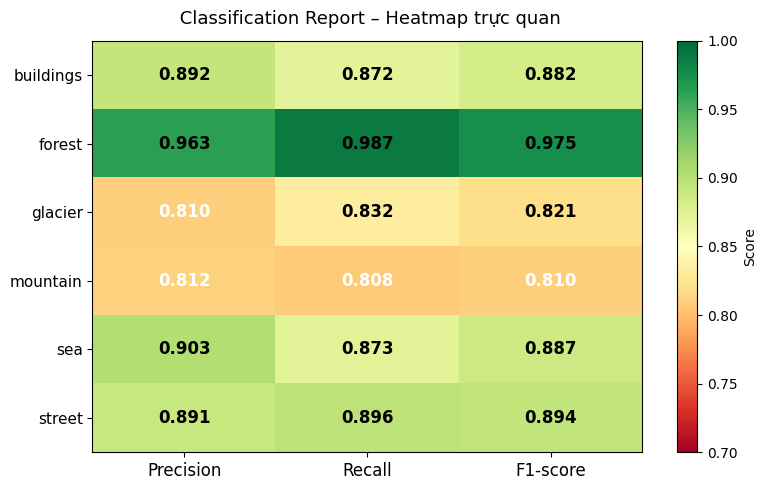

In [ ]:
report_dict = classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)


metrics = ['precision', 'recall', 'f1-score']
data = np.array([
    [report_dict[cls][m] for m in metrics]
    for cls in CLASS_NAMES
])

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(data, cmap='RdYlGn', vmin=0.70, vmax=1.0, aspect='auto')


ax.set_xticks(range(len(metrics)))
ax.set_xticklabels(['Precision', 'Recall', 'F1-score'], fontsize=12)
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_yticklabels(CLASS_NAMES, fontsize=11)

for i in range(len(CLASS_NAMES)):
    for j in range(len(metrics)):
        val = data[i, j]
        color = 'white' if val < 0.82 else 'black'
        ax.text(j, i, f'{val:.3f}', ha='center', va='center',
                fontsize=12, fontweight='bold', color=color)

plt.colorbar(im, ax=ax, label='Score')
ax.set_title(' Classification Report – Heatmap trực quan', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

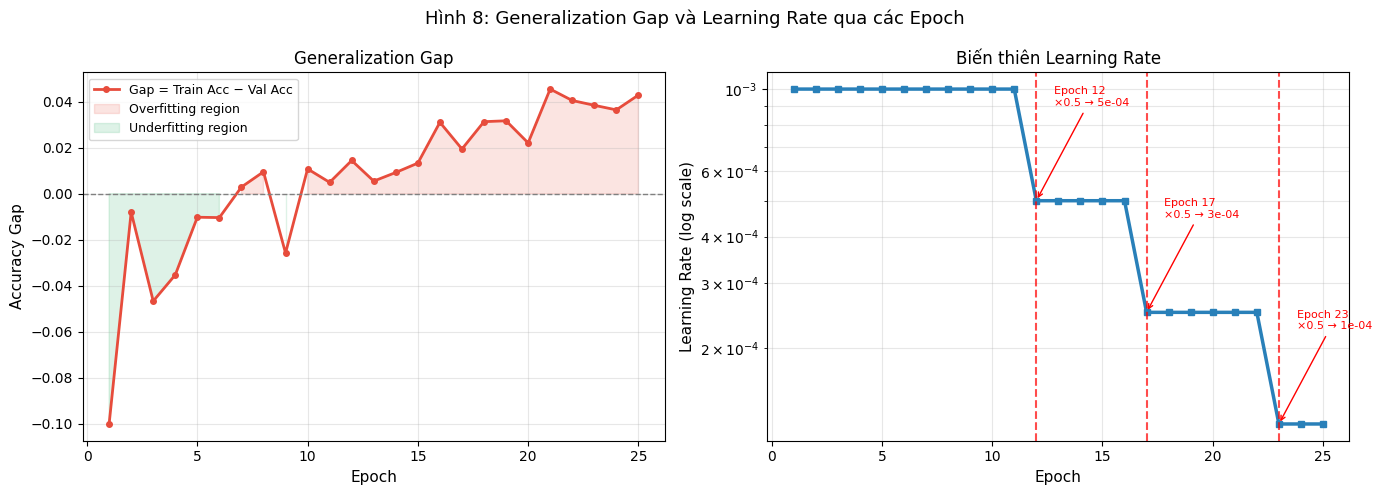

In [ ]:
def simulate_lr(val_loss_list, initial_lr=1e-3, factor=0.5, patience=3, min_lr=1e-6):
    lr = initial_lr
    lr_history = []
    best_loss = float('inf')
    wait = 0

    for loss in val_loss_list:
        if loss < best_loss:
            best_loss = loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                lr = max(lr * factor, min_lr)
                wait = 0
        lr_history.append(lr)
    return lr_history

# ── Lấy history ──────────────────────────────────────────────────────────────
# Nếu dùng joblib:  hist = history  (đã load từ pkl)
# Nếu dùng object:  hist = baseline_history.history
hist = baseline_history.history          # ← đổi nếu cần

train_acc = np.array(hist['accuracy'])
val_acc   = np.array(hist['val_accuracy'])
val_loss  = np.array(hist['val_loss'])
epochs    = np.arange(1, len(train_acc) + 1)
gap       = train_acc - val_acc

# Tính LR mô phỏng
lr_simulated = simulate_lr(val_loss, initial_lr=1e-3, factor=0.5, patience=3, min_lr=1e-6)

# ── Vẽ biểu đồ ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hình 8: Generalization Gap và Learning Rate qua các Epoch', fontsize=13)

# --- Subplot trái: Generalization Gap ---
axes[0].plot(epochs, gap, color='#E74C3C', linewidth=2, marker='o',
             markersize=4, label='Gap = Train Acc − Val Acc')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].fill_between(epochs, 0, gap,
                     where=(gap > 0), alpha=0.15, color='#E74C3C', label='Overfitting region')
axes[0].fill_between(epochs, 0, gap,
                     where=(gap <= 0), alpha=0.15, color='#27AE60', label='Underfitting region')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Accuracy Gap', fontsize=11)
axes[0].set_title('Generalization Gap', fontsize=12)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# --- Subplot phải: Learning Rate ---
axes[1].plot(epochs, lr_simulated, color='#2980B9', linewidth=2.5,
             marker='s', markersize=5)
axes[1].set_yscale('log')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Learning Rate (log scale)', fontsize=11)
axes[1].set_title('Biến thiên Learning Rate', fontsize=12)
axes[1].grid(True, which='both', alpha=0.3)

# Đánh dấu các điểm LR giảm
lr_arr = np.array(lr_simulated)
lr_changes = np.where(np.diff(lr_arr) < 0)[0]
for idx in lr_changes:
    ep = epochs[idx + 1]
    new_lr = lr_arr[idx + 1]
    axes[1].axvline(x=ep, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
    axes[1].annotate(f'Epoch {ep}\n×0.5 → {new_lr:.0e}',
                     xy=(ep, new_lr),
                     xytext=(ep + 0.8, new_lr * 1.8),
                     fontsize=8, color='red',
                     arrowprops=dict(arrowstyle='->', color='red', lw=1))

plt.tight_layout()
plt.show()

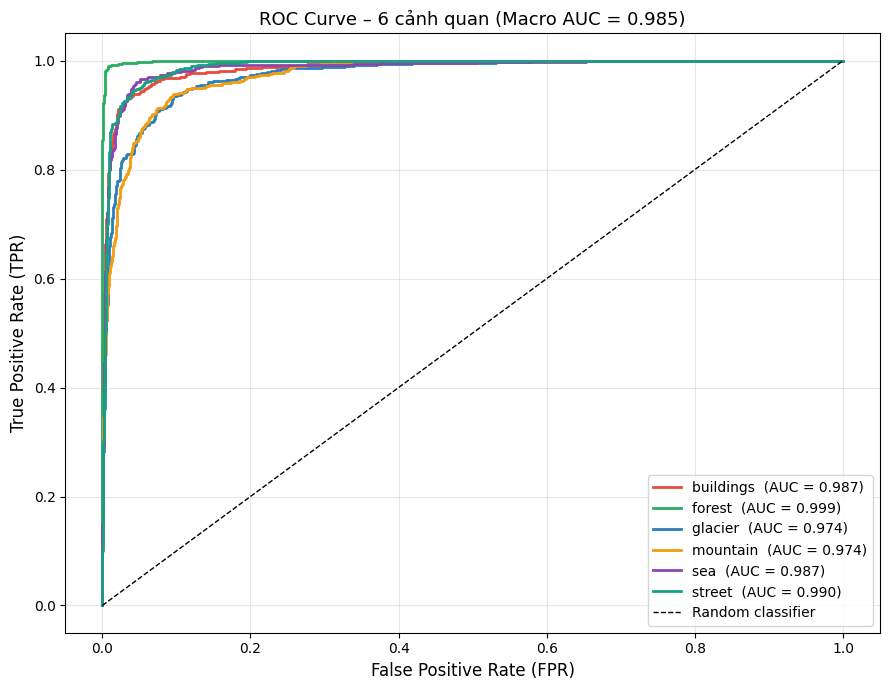


Bảng 3: ROC-AUC theo từng cảnh quan
Cảnh quan            AUC
-------------------------
buildings         0.9873
forest            0.9993
glacier           0.9744
mountain          0.9742
sea               0.9874
street            0.9897
-------------------------
Macro AUC         0.9854


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# y_true_bin và y_pred_prob đã được tính ở cell trước
# Nếu chưa có, bỏ comment 2 dòng dưới:
# y_true_bin  = label_binarize(y_true, classes=range(NUM_CLASSES))
# y_pred_prob = baseline_model.predict(test_gen)

colors_roc = ['#E74C3C', '#27AE60', '#2980B9',
               '#F39C12', '#8E44AD', '#16A085']

fig, ax = plt.subplots(figsize=(9, 7))

auc_per_class = {}
for i, cls in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc_cls  = auc(fpr, tpr)
    auc_per_class[cls] = roc_auc_cls
    ax.plot(fpr, tpr, color=colors_roc[i], linewidth=2,
            label=f'{cls}  (AUC = {roc_auc_cls:.3f})')

# Macro AUC
macro_auc = np.mean(list(auc_per_class.values()))

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax.set_xlabel('False Positive Rate (FPR)', fontsize=12)
ax.set_ylabel('True Positive Rate (TPR)', fontsize=12)
ax.set_title(f'ROC Curve – 6 cảnh quan (Macro AUC = {macro_auc:.3f})',
             fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# In bảng AUC từng lớp
print("\nBảng 3: ROC-AUC theo từng cảnh quan")
print(f"{'Cảnh quan':<15} {'AUC':>8}")
print("-" * 25)
for cls, val in auc_per_class.items():
    print(f"{cls:<15} {val:>8.4f}")
print("-" * 25)
print(f"{'Macro AUC':<15} {macro_auc:>8.4f}")


# **DỰ ĐOÁN ẢNH** ngay tại google colab . Cần up file ảnh lên rồi đổi tên ở dưới như tên ảnh. Nếu muốn test trên web thì truy cập theo link: https://huggingface.co/spaces/Dastsimcu/CNN

In [ ]:
#Dự đoán Ảnh
from tensorflow.keras.utils import load_img, img_to_array #dự đoán ảnh vào các class
import numpy as np

IMG_SIZE = 150
#tên ảnh là gì thì thay vào chỗ img_path ="........"
img_path = "dat4.jpg"
img = load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))

img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

pred_prob = baseline_model.predict(img_array)

pred_idx = np.argmax(pred_prob, axis=1)[0]
pred_class = CLASS_NAMES[pred_idx]

print("Prediction:", pred_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Prediction: street


In [ ]:
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: {pred_prob[0][i]:.4f}")

buildings: 0.0143
forest: 0.0000
glacier: 0.0000
mountain: 0.0000
sea: 0.0000
street: 0.9857


**LƯU MÔ HÌNH**

In [ ]:
baseline_model.save("baseline_model.keras") #save model

In [ ]:
import joblib #save model

joblib.dump(baseline_history.history, "baseline_history.pkl")

['baseline_history.pkl']